# Aşama 5 — GraphFrames ile Graf Analizi

Elliptic++ iki graf içeriyor ve ikisini de inceliyoruz:

| Graf | Düğüm | Kenar | Anlamı |
|---|---|---|---|
| **İşlem grafı** | 203.769 işlem | 234.355 | tx₁ → tx₂: tx₁'in bir çıktısı tx₂'ye girdi olmuş (BTC akışı) |
| **Adres grafı** | 822.942 cüzdan | 2.775.637 (temizlenmiş) | addr₁ → addr₂: aynı işlemde addr₁ gönderici, addr₂ alıcı |

**Neden GraphX değil de GraphFrames?** GraphX'in yalnızca Scala/Java API'si var. GraphFrames ise düğüm ve kenarları Spark DataFrame olarak tutuyor ve Python'dan kullanılabiliyor. Ayrıca motif arama (`find`) ile graf sorgularını Catalyst optimizer'a gönderebiliyor.

Uygulanan algoritmalar: **derece analizi**, **connected components**, **PageRank**, **motif arama**.

In [1]:
import sys, pathlib
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "common").is_dir())
sys.path.insert(0, str(ROOT))
from common.spark_utils import *  # get_spark, RAW, PROC, MODELS, CHECKPOINTS, TRAIN_MAX_STEP ...
import pandas as pd
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)

In [2]:
from pyspark.sql import functions as F
from graphframes import GraphFrame
import matplotlib.pyplot as plt, numpy as np, time

spark = get_spark("05-graphframes", {"spark.sql.shuffle.partitions": "32"})
print("checkpoint dizini:", spark.sparkContext.getCheckpointDir())

:: loading settings :: url = jar:file:/usr/local/lib/python3.13/dist-packages/pyspark/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


checkpoint dizini: checkpoints/graph/1c814abc-60f3-4072-a939-5ac330be85c3


# A. İşlem grafı

In [3]:
v = (spark.read.parquet(str(PROC / "txs"))
     .select(F.col("txId").alias("id"), "time_step", "class_name", "label",
             "num_input_addresses", "num_output_addresses", "out_BTC_total"))
e = spark.read.parquet(str(PROC / "tx_edges"))            # src, dst
g = GraphFrame(v, e)
g.vertices.cache(); g.edges.cache()
print(f"düğüm: {g.vertices.count():,}  kenar: {g.edges.count():,}")

düğüm: 203,769  kenar: 234,355


## A1 · Derece analizi

In [4]:
deg = (g.vertices.join(g.inDegrees, "id", "left").join(g.outDegrees, "id", "left")
         .fillna(0, ["inDegree", "outDegree"]).cache())
deg.groupBy("class_name").agg(
    F.count("*").alias("n"),
    F.round(F.avg("inDegree"), 3).alias("ort_in"), F.round(F.avg("outDegree"), 3).alias("ort_out"),
    F.max("inDegree").alias("maks_in"), F.max("outDegree").alias("maks_out"),
    F.round(F.avg((F.col("inDegree") == 0).cast("int")), 3).alias("kaynak_orani(in=0)"),
    F.round(F.avg((F.col("outDegree") == 0).cast("int")), 3).alias("havuz_orani(out=0)"),
).orderBy("class_name").toPandas()

,class_name,n,ort_in,ort_out,maks_in,maks_out,kaynak_orani(in=0),havuz_orani(out=0)
0,illicit,4545,1.270,0.742,177,3,0.265,0.326
1,licit,42019,1.909,1.186,284,472,0.332,0.245
2,unknown,157205,0.944,1.152,212,122,0.256,0.163


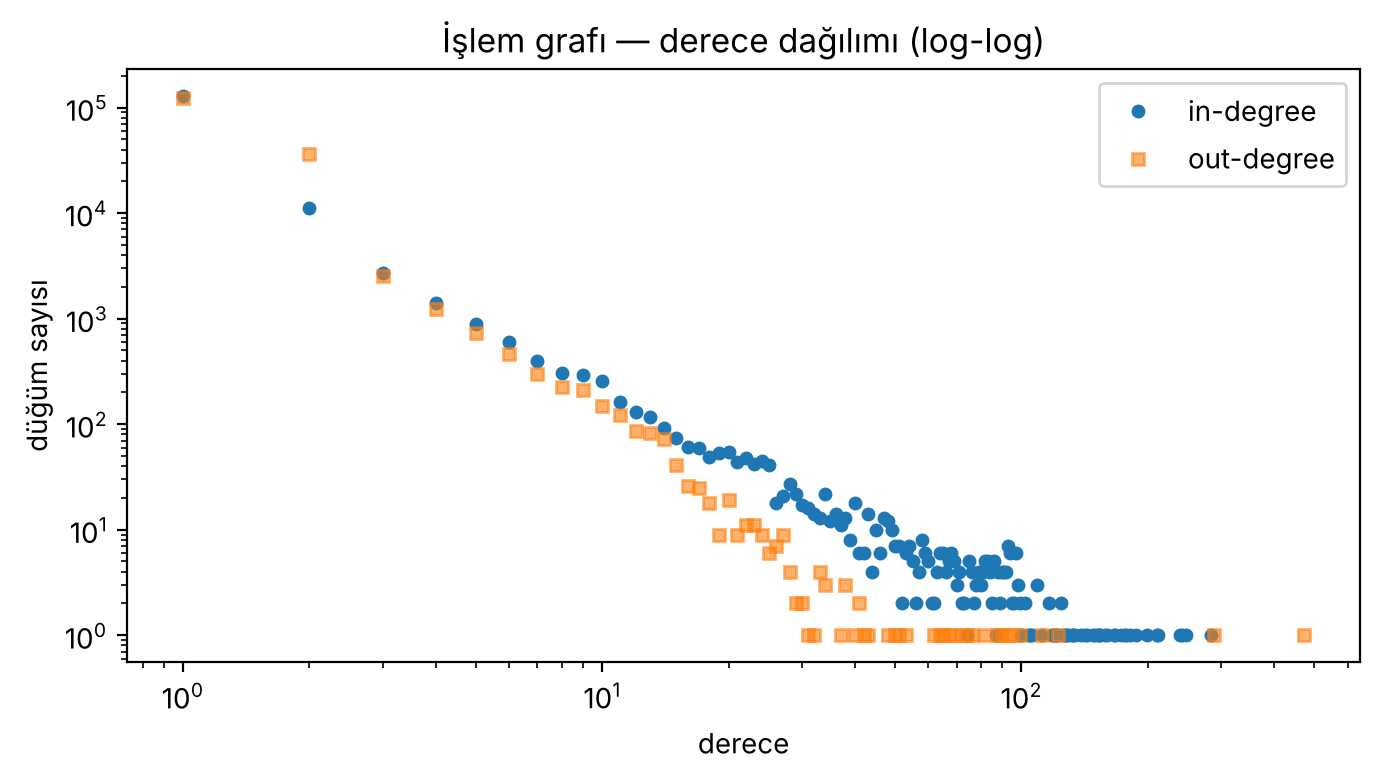

In [5]:
dd = deg.groupBy("inDegree").count().toPandas().sort_values("inDegree")
od = deg.groupBy("outDegree").count().toPandas().sort_values("outDegree")
fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(dd.inDegree[dd.inDegree > 0], dd["count"][dd.inDegree > 0], "o", ms=4, label="in-degree")
ax.loglog(od.outDegree[od.outDegree > 0], od["count"][od.outDegree > 0], "s", ms=4, alpha=.6, label="out-degree")
ax.set_xlabel("derece"); ax.set_ylabel("düğüm sayısı"); ax.set_title("İşlem grafı — derece dağılımı (log-log)"); ax.legend()
plt.tight_layout(); plt.show()

## A2 · Connected components

Her bileşen, aralarında (yönsüz) BTC akışı yolu bulunan işlemlerin kümesi. Hesaplama iteratif ve her iterasyonda lineage uzadığı için GraphFrames ara sonuçları checkpoint dizinine yazıyor (`setCheckpointDir`).

In [6]:
t = time.time()
cc = g.connectedComponents().cache()
n_cc = cc.select("component").distinct().count()
print(f"bileşen sayısı: {n_cc}   ({time.time() - t:.1f} sn)")
comp = cc.groupBy("component").agg(F.count("*").alias("boyut"),
                                    F.countDistinct("time_step").alias("farkli_adim"),
                                    F.min("time_step").alias("adim"),
                                    F.sum((F.col("class_name") == "illicit").cast("int")).alias("illicit"))
comp.select(F.max("farkli_adim").alias("bir bileşendeki maks. farklı zaman adımı"),
            F.min("boyut").alias("min boyut"), F.max("boyut").alias("maks boyut"),
            F.round(F.avg("boyut"), 0).alias("ort boyut")).show()

bileşen sayısı: 49   (60.3 sn)


+----------------------------------------+---------+----------+---------+
|bir bileşendeki maks. farklı zaman adımı|min boyut|maks boyut|ort boyut|
+----------------------------------------+---------+----------+---------+
|                                       1|     1089|      7880|   4159.0|
+----------------------------------------+---------+----------+---------+



**Bulgu:** Her bileşen tek bir zaman adımına ait. Yani veri seti, her zaman adımı kendi içinde bağlı ve adımlar birbirine bağlanmayacak şekilde kurulmuş (Elliptic'in açıklamasıyla da tutarlı). Bunun iki sonucu var: (1) Aşama 2'deki zamansal bölmede eğitim ve test grafları arasında **kenar sızıntısı yok**. (2) Komşuluk bilgisi yalnızca aynı adım içinden geliyor.

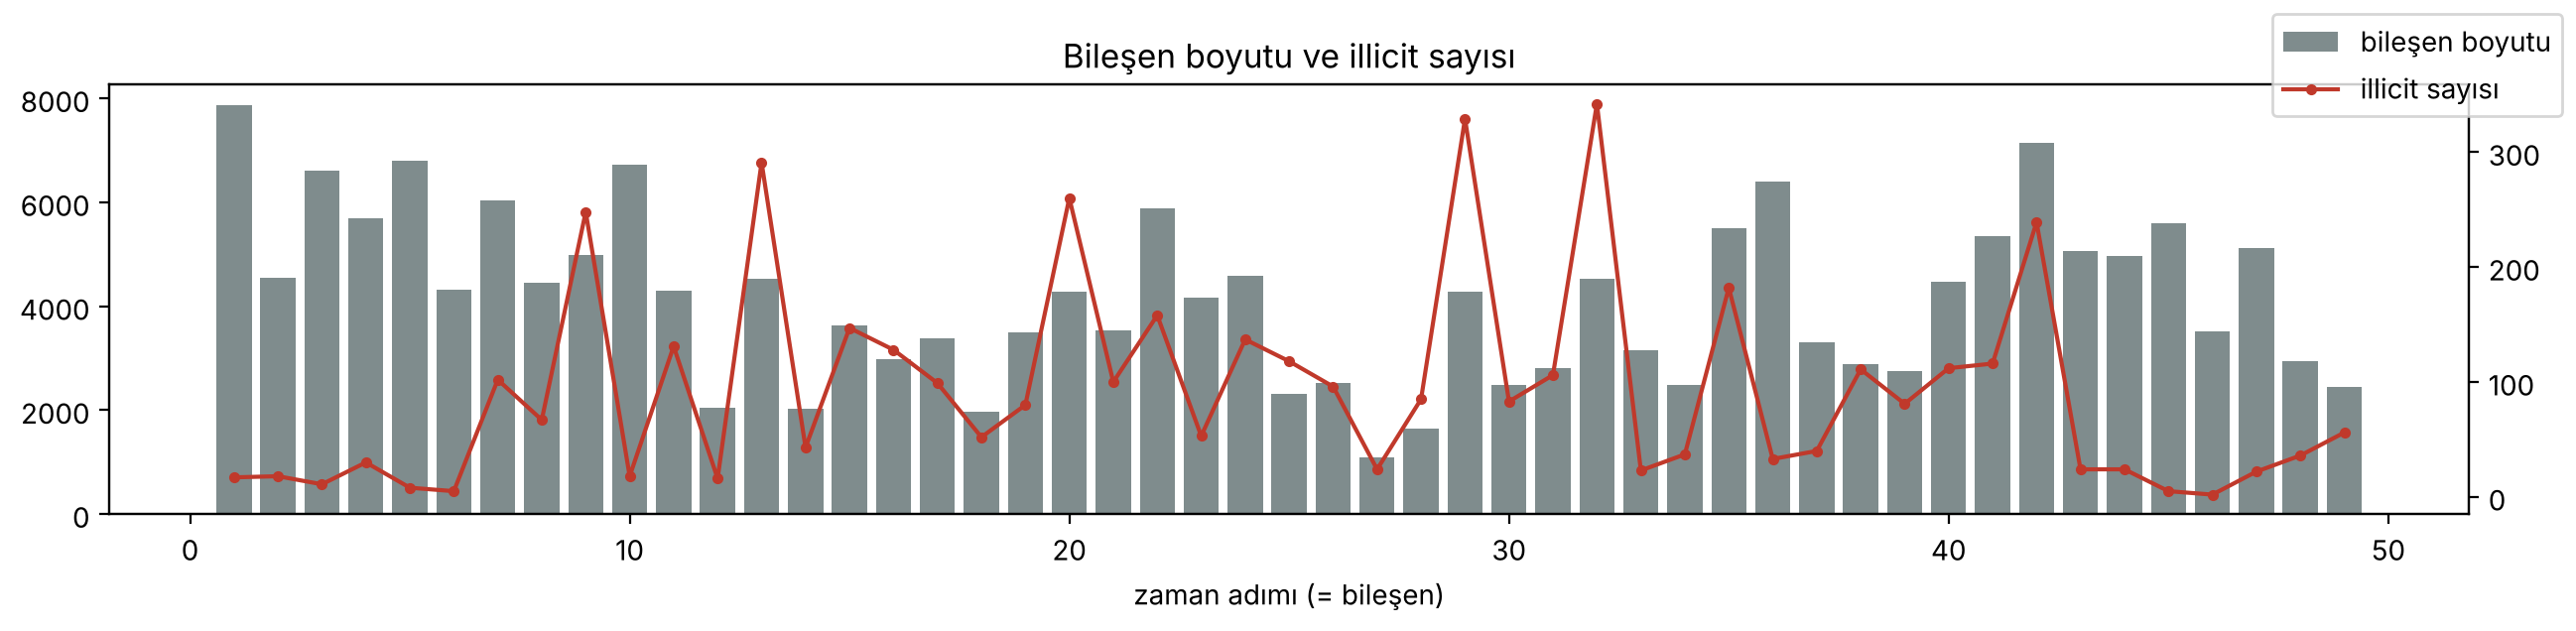

In [7]:
cp = comp.orderBy("adim").toPandas()
fig, ax = plt.subplots(figsize=(13, 3.2))
ax.bar(cp.adim, cp.boyut, color="#7f8c8d", label="bileşen boyutu")
ax2 = ax.twinx(); ax2.plot(cp.adim, cp.illicit, "o-", c="#c0392b", ms=3, label="illicit sayısı")
ax.set_xlabel("zaman adımı (= bileşen)"); ax.set_title("Bileşen boyutu ve illicit sayısı"); fig.legend(loc="upper right"); plt.tight_layout(); plt.show()

## A3 · PageRank

PageRank'i BTC akış yönünde çalıştırıyoruz. Yüksek skor, **çok sayıda akışın (dolaylı olarak) ulaştığı** işlemleri işaret ediyor; yani fonların toplandığı noktaları.

In [8]:
t = time.time()
pr = g.pageRank(resetProbability=0.15, maxIter=10)
prv = pr.vertices.cache(); prv.count()
print(f"PageRank: {time.time() - t:.1f} sn")
prv.orderBy(F.desc("pagerank")).select("id", "time_step", "class_name", F.round("pagerank", 2).alias("pagerank"),
                                       "num_input_addresses", "num_output_addresses").show(10)

PageRank: 11.4 sn


+---------+---------+----------+--------+-------------------+--------------------+
|       id|time_step|class_name|pagerank|num_input_addresses|num_output_addresses|
+---------+---------+----------+--------+-------------------+--------------------+
| 43388675|       10|     licit|   96.59|              360.0|                 1.0|
|225859042|        5|   unknown|   95.91|              277.0|                 2.0|
| 99409352|       40|     licit|   92.21|               22.0|                 2.0|
|179084283|        9|   unknown|   89.44|               98.0|                 2.0|
| 30276715|       37|     licit|   87.75|              136.0|                 2.0|
|121801433|        6|   unknown|   81.58|               96.0|                 2.0|
| 91882349|       43|     licit|   77.25|              101.0|                31.0|
|163832295|       29|     licit|   72.05|               39.0|                 2.0|
|121654821|        6|   unknown|    71.4|              205.0|                 2.0|
| 96

In [9]:
from pyspark.sql.window import Window
ranked = prv.withColumn("rank", F.row_number().over(Window.orderBy(F.desc("pagerank"))))
rows = []
for k in (100, 1000, 10000, None):
    sub = ranked if k is None else ranked.filter(F.col("rank") <= k)
    r = sub.agg(F.count("*").alias("n"),
                F.avg((F.col("class_name") == "illicit").cast("int")).alias("illicit"),
                F.avg((F.col("class_name") == "licit").cast("int")).alias("licit"),
                F.avg((F.col("class_name") == "unknown").cast("int")).alias("unknown")).first()
    rows.append({"küme": f"PageRank ilk {k}" if k else "tüm graf", **{c: round(r[c], 4) for c in ("illicit", "licit", "unknown")}})
pd.DataFrame(rows)

,küme,illicit,licit,unknown
0,PageRank ilk 100,0.0600,0.7300,0.2100
1,PageRank ilk 1000,0.0230,0.6200,0.3570
2,PageRank ilk 10000,0.0097,0.2913,0.6990
3,tüm graf,0.0223,0.2062,0.7715


## A4 · Motif arama: illicit para zincirleri

`g.find("(a)-[]->(b); (b)-[]->(c)")` tüm 2 adımlı akış yollarını (a → b → c) bulur. Arka planda iki kenar tablosunun join'i olarak çalışır. Sorduğumuz soru: Zincirin ilk iki halkası illicit ise, üçüncü halkanın da illicit olma olasılığı nedir? Taban oran (~%10) ile kıyaslıyoruz.

In [10]:
paths = g.find("(a)-[]->(b); (b)-[]->(c)")
labeled_paths = paths.filter("a.label IS NOT NULL AND b.label IS NOT NULL AND c.label IS NOT NULL").cache()
print(f"2 adımlı yol: {paths.count():,} | tamamı etiketli: {labeled_paths.count():,}")

pat = (labeled_paths.groupBy(F.col("a.class_name").alias("a"), F.col("b.class_name").alias("b"))
       .agg(F.count("*").alias("yol"), F.round(F.avg("c.label"), 4).alias("P(c illicit)"))
       .orderBy("a", "b").toPandas())
base = labeled_paths.agg(F.avg("c.label")).first()[0]
pat["taban orana göre kat"] = (pat["P(c illicit)"] / base).round(1)
print(f"taban oran P(c illicit) = {base:.4f}"); pat

2 adımlı yol: 254,031 | tamamı etiketli: 27,318


taban oran P(c illicit) = 0.0340


,a,b,yol,P(c illicit),taban orana göre kat
0,illicit,illicit,696,0.8348,24.5
1,illicit,licit,425,0.0094,0.3
2,licit,illicit,80,0.4875,14.3
3,licit,licit,26117,0.0117,0.3


In [11]:
chains = labeled_paths.filter("a.label = 1 AND b.label = 1 AND c.label = 1")
licit_chains = labeled_paths.filter("a.label = 0 AND b.label = 0 AND c.label = 0")
def profile(df, name):
    return df.agg(F.lit(name).alias("zincir"), F.count("*").alias("adet"),
                  F.round(F.avg("b.num_output_addresses"), 2).alias("b ort. çıktı"),
                  F.round(F.avg("b.num_input_addresses"), 2).alias("b ort. girdi"),
                  F.round(F.expr("percentile_approx(b.out_BTC_total, 0.5)"), 4).alias("b medyan BTC")).toPandas()
pd.concat([profile(chains, "illicit→illicit→illicit"), profile(licit_chains, "licit→licit→licit")])

,zincir,adet,b ort. çıktı,b ort. girdi,b medyan BTC
0,illicit→illicit→illicit,581,1.99,1.80,3.2021
0,licit→licit→licit,25812,293.63,21.22,11.8987


# B. Adres (cüzdan) grafı

In [12]:
av = (spark.read.parquet(str(PROC / "wallet_classes")).select(F.col("address").alias("id"), "class_name", "label"))
ae = spark.read.parquet(str(PROC / "addr_edges"))
ag = GraphFrame(av, ae)
ag.vertices.cache(); ag.edges.cache()
print(f"düğüm: {ag.vertices.count():,}  kenar: {ag.edges.count():,}")

düğüm: 822,942  kenar: 2,775,637


## B1 · Derece dağılımı: ölçekten bağımsız (scale-free) mı?

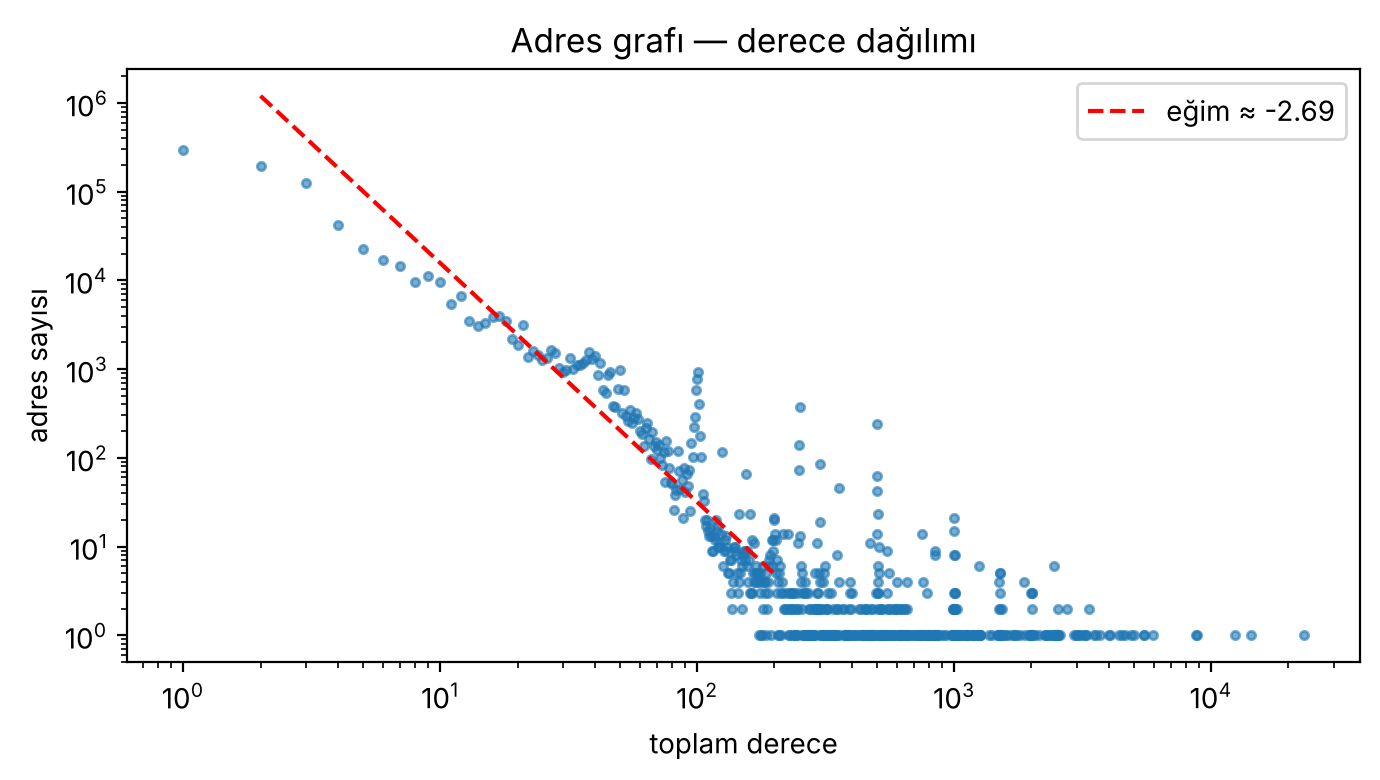

log-log eğim (derece 2-200): -2.69


+----------+------+----------+------+-----+
|class_name|     n|ort_derece|medyan| maks|
+----------+------+----------+------+-----+
|   illicit| 14266|      3.63|     2| 1998|
|     licit|251088|     10.58|     2|22996|
|   unknown|557588|       5.1|     2| 8855|
+----------+------+----------+------+-----+



In [13]:
adeg = (ag.vertices.join(ag.inDegrees, "id", "left").join(ag.outDegrees, "id", "left")
          .fillna(0, ["inDegree", "outDegree"]).withColumn("degree", F.col("inDegree") + F.col("outDegree")).cache())
hist = adeg.groupBy("degree").count().toPandas().sort_values("degree")
h = hist[hist.degree > 0]
mask = (h.degree >= 2) & (h.degree <= 200)
slope, intercept = np.polyfit(np.log10(h.degree[mask]), np.log10(h["count"][mask]), 1)
fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(h.degree, h["count"], "o", ms=3, alpha=.6)
xs = np.array([2, 200]); ax.loglog(xs, 10 ** (intercept + slope * np.log10(xs)), "r--", label=f"eğim ≈ {slope:.2f}")
ax.set_xlabel("toplam derece"); ax.set_ylabel("adres sayısı"); ax.set_title("Adres grafı — derece dağılımı"); ax.legend()
plt.tight_layout(); plt.show()
print(f"log-log eğim (derece 2-200): {slope:.2f}")
adeg.groupBy("class_name").agg(F.count("*").alias("n"), F.round(F.avg("degree"), 2).alias("ort_derece"),
                               F.expr("percentile_approx(degree, 0.5)").alias("medyan"), F.max("degree").alias("maks")).orderBy("class_name").show()

## B2 · Komşuluk homofilisi: illicit cüzdanlar kiminle etkileşiyor?

In [14]:
nb = (ag.edges.join(av.select(F.col("id").alias("src"), F.col("class_name").alias("src_class")), "src")
              .join(av.select(F.col("id").alias("dst"), F.col("class_name").alias("dst_class")), "dst"))
(nb.groupBy("src_class").pivot("dst_class", ["illicit", "licit", "unknown"]).count()
   .withColumn("toplam", F.col("illicit") + F.col("licit") + F.col("unknown"))
   .select("src_class", *[F.round(F.col(c) / F.col("toplam"), 4).alias(f"→ {c}") for c in ["illicit", "licit", "unknown"]], "toplam")
   .orderBy("src_class").show())

+---------+---------+-------+---------+-------+
|src_class|→ illicit|→ licit|→ unknown| toplam|
+---------+---------+-------+---------+-------+
|  illicit|   0.8798| 0.0725|   0.0477|  17563|
|    licit|   0.0065| 0.8342|   0.1594|1278904|
|  unknown|   0.0071| 0.2097|   0.7832|1479170|
+---------+---------+-------+---------+-------+



## B3 · PageRank ve connected components (2.8M kenar)

In [15]:
t = time.time()
apr = ag.pageRank(resetProbability=0.15, maxIter=5).vertices.cache()
apr.count(); t_pr = time.time() - t
t = time.time()
acc = ag.connectedComponents().cache()
sizes = acc.groupBy("component").count().cache()
n_comp = sizes.count(); t_cc = time.time() - t
giant = sizes.agg(F.max("count")).first()[0]
print(f"PageRank: {t_pr:.1f} sn | connected components: {t_cc:.1f} sn")
print(f"bileşen sayısı: {n_comp:,} | en büyük bileşen: {giant:,} adres (%{100 * giant / av.count():.1f})")
apr.orderBy(F.desc("pagerank")).select("id", "class_name", F.round("pagerank", 1).alias("pagerank")).show(10, truncate=False)

PageRank: 74.8 sn | connected components: 59.3 sn
bileşen sayısı: 2 | en büyük bileşen: 822,935 adres (%100.0)


+----------------------------------+----------+--------+
|id                                |class_name|pagerank|
+----------------------------------+----------+--------+
|1FAv42GaDuQixSzEzSbx6aP1Kf4WVWpQUY|licit     |3382.0  |
|12cgpFdJViXbwHbhrA3TuW1EGnL25Zqc3P|licit     |2494.5  |
|3QuHejbAAbeRoTkH5wBwGzMipf4R3zpQga|unknown   |1643.0  |
|13vHWR3iLsHeYwT42RnuKYNBoVPrKKZgRv|licit     |1517.0  |
|17Akhagbr3iz9jZQDPgNmr1kkRW3NNf8EW|unknown   |1297.9  |
|1FvtWwP3ePJDeR6K7ZePGujUuusUTds8Vy|illicit   |1296.9  |
|3Kfke8cAB7fbxnBmpSyWtK6tWMFFt1frzs|unknown   |1067.4  |
|3LjVb2kHrYZkRWxKVXXrhzdgKu4yBt1CHH|unknown   |1015.7  |
|3KxL1s5SJjLXd82uhTZgg3EZdGPSUzt7tA|unknown   |1015.7  |
|1Vt1x5KDXfEewCsxsT1HYRwQthdNREY8a |unknown   |847.8   |
+----------------------------------+----------+--------+
only showing top 10 rows



In [16]:
giant_id = sizes.orderBy(F.desc("count")).first()["component"]
(acc.withColumn("bileşen", F.when(F.col("component") == giant_id, "dev bileşen").otherwise("diğer"))
    .groupBy("bileşen").agg(F.count("*").alias("adres"),
                            F.round(F.avg((F.col("class_name") == "illicit").cast("int")), 4).alias("illicit oranı"),
                            F.round(F.avg((F.col("class_name") == "licit").cast("int")), 4).alias("licit oranı"))
    .show())

+-----------+------+-------------+-----------+
|    bileşen| adres|illicit oranı|licit oranı|
+-----------+------+-------------+-----------+
|dev bileşen|822935|       0.0173|     0.3051|
|      diğer|     7|          0.0|        0.0|
+-----------+------+-------------+-----------+



## Sonuçların yorumu

**İşlem grafı**
* **Yapı:** Tam olarak **49 bağlı bileşen** var ve her biri tek bir zaman adımı (boyutları 1.089 ile 7.880 düğüm arasında). Graf, adımlar arası kenar içermeyecek şekilde kurulmuş. Bu yüzden zamansal bölmede graf üzerinden sızıntı olmuyor.
* **Derece:** Illicit işlemlerin **maksimum out-degree değeri 3**; licit işlemlerde 472'ye kadar çıkıyor. Illicit para geniş yelpazeye dağıtılmıyor, dar kanallardan akıyor. Derece dağılımı ağır kuyruklu: Düğümlerin çoğunun derecesi 1–2, ama birkaç yüz dereceli hub'lar da var.
* **PageRank:** En yüksek skorlu işlemler yüzlerce girdiyi tek çıktıda birleştiren **konsolidasyon** işlemleri (360, 277, 534 girdili). İlk 100'ün %73'ü licit. İlk 1.000'deki illicit oranı (%2.3) tüm graftakiyle (%2.2) neredeyse aynı. PageRank "önemli" düğümleri buluyor, "şüpheli" düğümleri değil; tek başına bir tespit sinyali sayılmaz.
* **Motif, en güçlü bulgu:** a → b → c zincirinde a ve b illicit ise **P(c illicit) = 0.835**; tamamı etiketli yollarda taban oran 0.034. Yani **24.5 kat** fazla. Licit → illicit geçişinden sonra bile oran 0.49 (14 kat). Tamamen illicit zincirler ince ve doğrusal: Ara halkanın ortalama girdi sayısı **1.8** ve çıktı sayısı **2.0**; licit zincirlerde bu değerler **21.2** ve **293.6** (toplu ödeme, ör. borsa payout işlemleri). Medyan tutar 3.2 BTC'ye karşı 11.9 BTC. Bu, fonların çok girdili karıştırma noktalarından geçmeden, düğümden düğüme sırayla aktarıldığı bir zincir yapısı.

**Adres grafı**
* **Derece dağılımı:** Log-log grafikte yaklaşık doğrusal ve eğimi ≈ −2.69 (derece 2–200 aralığında kaba bir en küçük kareler tahmini; kuyruktaki tekil gözlemler eğimi etkiliyor). Bu, ölçekten bağımsız (scale-free) ağlara özgü bir kuvvet yasası. Birkaç devasa hub (en yüksek derece 22.996, licit) ve çok sayıda düşük dereceli adres var.
* **Bağlantılılık:** 822.942 adresin 822.935'i **tek bir dev bileşende**. Borsa benzeri hub'lar 49 zaman adımını birbirine bağlıyor. Connected components bu grafta aktörleri ayırmak için işe yaramıyor; ayırt edici bilgi bileşen düzeyinde değil, **komşuluk düzeyinde**.
* **Homofili:** Illicit cüzdanlardan çıkan kenarların **%88'i yine illicit** cüzdanlara gidiyor; illicit cüzdanların genel oranı ise %1.7 (~50 kat). Licit ve unknown cüzdanlardan illicit'e giden kenar oranı %1'in altında. Bu, Aşama 4 S6'daki "dar çevre" gözlemini graf düzeyinde doğruluyor. Illicit aktörler kendi aralarında kapalı bir alt ağ oluşturuyor; bu da etiket yayılımı (label propagation) veya GNN tabanlı yöntemler için güçlü bir gerekçe.

**Ölçek notu:** 2.8M kenarlı adres grafında PageRank (5 iterasyon) ve connected components, 2 çekirdekli local mode'da yaklaşık birer dakika sürdü. İkisi de iteratif: Her iterasyon bir join ve bir shuffle demek; lineage'in büyümesini checkpoint keser.

In [17]:
spark.stop()